# Retail Demand Forecasting and Replenishment
**EN:** Daily sales forecasts for Favorita stores, then an inventory simulation that uses them. The code is in `src/`; this notebook runs the steps.

**TR:** Favorita mağazaları için günlük satış tahmini, ardından bu tahminleri kullanan bir stok simülasyonu. Kod `src/` klasöründe; bu notebook adımları çalıştırır.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src import data

pd.set_option("display.width", 120)
data.FIG_DIR.mkdir(parents=True, exist_ok=True)

## Step 1: Data check / Adım 1: Veri kontrolü
**EN:** We check size, dates, missing values, zero sales and the trend. Then we pick a scope that runs fast on a laptop.

**TR:** Boyut, tarih, eksik değer, sıfır satış ve trende bakıyoruz. Sonra laptopta hızlı çalışan bir kapsam seçiyoruz.

In [2]:
# Full training file: size, dates, missing values
# Tüm eğitim dosyası: boyut, tarihler, eksik değerler
train = data.load_train()
print("rows:", len(train), "| stores:", train.store_nbr.nunique(), "| families:", train.family.nunique())
print("dates:", train.date.min().date(), "->", train.date.max().date())

# Missing calendar days (stores closed on Dec 25)
# Takvimde eksik günler (25 Aralık mağazalar kapalı)
full = pd.date_range(train.date.min(), train.date.max())
print("missing days:", [d.date() for d in full.difference(train.date.unique())])
print("missing values per column:", train.isna().sum().to_dict())

rows: 3000888 | stores: 54 | families: 33
dates: 2013-01-01 -> 2017-08-15
missing days: [datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25), datetime.date(2016, 12, 25)]
missing values per column: {'date': 0, 'store_nbr': 0, 'family': 0, 'sales': 0, 'onpromotion': 0}


In [3]:
# Zero sales: how common, and which families
# Sıfır satışlar: ne kadar yaygın, hangi ailelerde
print("zero-sales share (all):", round((train.sales == 0).mean(), 3))
zero_by_fam = train.groupby("family", observed=True).sales.apply(lambda s: (s == 0).mean())
share_by_fam = train.groupby("family", observed=True).sales.sum() / train.sales.sum()
pd.DataFrame({"sales_share": share_by_fam, "zero_share": zero_by_fam}).sort_values("sales_share", ascending=False).round(3).head(15)

zero-sales share (all): 0.313


,sales_share,zero_share
family,,
GROCERY I,0.320,0.081
BEVERAGES,0.202,0.081
PRODUCE,0.114,0.284
CLEANING,0.091,0.081
DAIRY,0.060,0.081
BREAD/BAKERY,0.039,0.081
POULTRY,0.030,0.081
MEATS,0.029,0.081
PERSONAL CARE,0.023,0.081


In [4]:
# Other files: rows and missing values
# Diğer dosyalar: satır sayısı ve eksik değerler
for name, df in {"oil": pd.read_csv(data.DATA_DIR / "oil.csv"),
                 "holidays": data.load_holidays(),
                 "transactions": data.load_transactions(),
                 "stores": data.load_stores()}.items():
    print(f"{name:13s} rows={len(df):6d} missing={df.isna().sum().sum()}")
print(data.load_holidays().type.value_counts().to_dict())

oil           rows=  1218 missing=43
holidays      rows=   350 missing=0
transactions  rows= 83488 missing=0
stores        rows=    54 missing=0
{'Holiday': 221, 'Event': 56, 'Additional': 51, 'Transfer': 12, 'Bridge': 5, 'Work Day': 5}


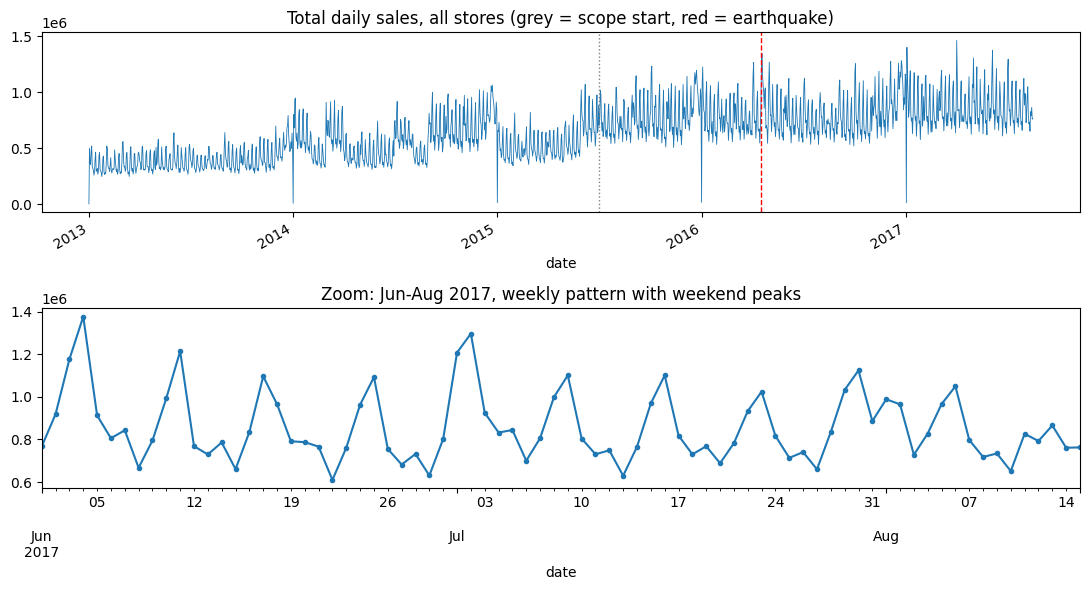

In [5]:
# Total sales over time; red line = 2016-04-16 earthquake
# Zaman içinde toplam satış; kırmızı çizgi = 16.04.2016 depremi
daily = train.groupby("date").sales.sum()
fig, ax = plt.subplots(2, 1, figsize=(11, 6))
daily.plot(ax=ax[0], lw=0.6)
ax[0].axvline(pd.Timestamp("2016-04-16"), color="red", ls="--", lw=1)
ax[0].axvline(pd.Timestamp(data.SCOPE_START), color="grey", ls=":", lw=1)
ax[0].set_title("Total daily sales, all stores (grey = scope start, red = earthquake)")
daily["2017-06-01":].plot(ax=ax[1], marker=".")
ax[1].set_title("Zoom: Jun-Aug 2017, weekly pattern with weekend peaks")
plt.tight_layout(); plt.savefig(data.FIG_DIR / "01_sales_over_time.png", dpi=110); plt.show()

In [6]:
# Chosen scope: all 54 stores x top-10 families, from 2015-07-01
# Seçilen kapsam: 54 mağaza x ilk 10 aile, 2015-07-01'den itibaren
df = data.load_scope()
n_series = df.groupby(["store_nbr", "family"], observed=True).ngroups
print("rows:", len(df), "| series:", n_series, "| dates:", df.date.min().date(), "->", df.date.max().date())
print("families:", list(df.family.cat.categories))
print("share of total sales covered:", round(df.sales.sum() / train.loc[train.date >= data.SCOPE_START, "sales"].sum(), 3))
print("zero-sales share in scope:", round((df.sales == 0).mean(), 3))

rows: 411250 | series: 540 | dates: 2015-07-01 -> 2017-08-15
families: ['BEVERAGES', 'BREAD/BAKERY', 'CLEANING', 'DAIRY', 'DELI', 'GROCERY I', 'MEATS', 'PERSONAL CARE', 'POULTRY', 'PRODUCE']
share of total sales covered: 0.93
zero-sales share in scope: 0.01


## Step 2: Baselines / Adım 2: Baseline modeller
**EN:** Naive repeats the last known day; seasonal naive repeats the same weekday of the last known week. We score both on 4 rolling 16-day windows, using only data up to each cutoff.

**TR:** Naive bilinen son günü tekrarlar; seasonal naive bilinen son haftanın aynı gününü tekrarlar. İkisini 4 kayan 16 günlük pencerede, sadece cutoff'a kadarki veriyle puanlıyoruz.

In [7]:
from src import baselines, evaluate

# Backtest windows: cutoff = last day the model may see
# Backtest pencereleri: cutoff = modelin görebileceği son gün
folds = evaluate.make_folds()
folds

,fold,cutoff,test_start,test_end
0,1,2017-06-12,2017-06-13,2017-06-28
1,2,2017-06-28,2017-06-29,2017-07-14
2,3,2017-07-14,2017-07-15,2017-07-30
3,4,2017-07-30,2017-07-31,2017-08-15


In [8]:
# Run both baselines on every fold and score them
# Her iki baseline'ı her fold'da çalıştır ve puanla
KEYS = ["date", "store_nbr", "family"]
base_preds, rows = [], []
for f in folds.itertuples():
    actual = df[(df.date >= f.test_start) & (df.date <= f.test_end)][KEYS + ["sales"]]
    for name, fn in {"naive": baselines.naive, "seasonal_naive": baselines.seasonal_naive}.items():
        pred = fn(df[df.date <= f.cutoff], f.cutoff, evaluate.HORIZON)
        m = actual.merge(pred, on=KEYS, how="left").assign(fold=f.fold, model=name)
        base_preds.append(m)
        rows.append({"fold": f.fold, "model": name, **evaluate.metrics(m.sales, m.pred)})
base_preds = pd.concat(base_preds, ignore_index=True)
base_scores = pd.DataFrame(rows)
base_scores.pivot(index="fold", columns="model", values=["MAE", "RMSE", "WAPE"]).round(3)

MAE                     RMSE                  WAPE               
model    naive seasonal_naive     naive seasonal_naive  naive seasonal_naive
fold                                                                        
1      316.016        227.921   716.284        532.965  0.225          0.162
2      444.873        232.726  1039.506        579.011  0.298          0.156
3      383.811        195.402   857.639        482.172  0.259          0.132
4      627.933        282.462  1313.135        628.457  0.438          0.197

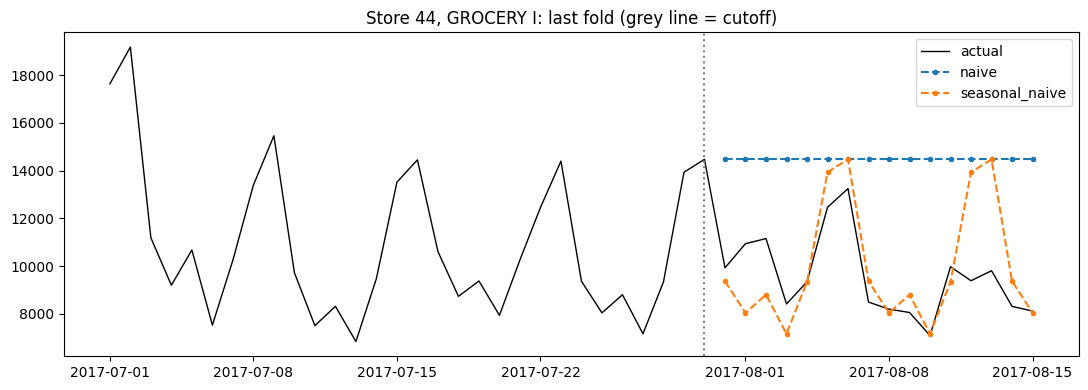

In [9]:
# Example series in the last fold: actual vs. baselines
# Son fold'da örnek bir seri: gerçek satış ve baseline'lar
ex = base_preds[(base_preds.fold == 4) & (base_preds.store_nbr == 44) & (base_preds.family == "GROCERY I")]
hist = df[(df.store_nbr == 44) & (df.family == "GROCERY I") & (df.date >= "2017-07-01")]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hist.date, hist.sales, color="black", lw=1, label="actual")
for name, g in ex.groupby("model"):
    ax.plot(g.date, g.pred, ls="--", marker=".", label=name)
ax.axvline(folds.cutoff.iloc[-1], color="grey", ls=":")
ax.set_title("Store 44, GROCERY I: last fold (grey line = cutoff)"); ax.legend()
plt.tight_layout(); plt.savefig(data.FIG_DIR / "02_baselines_example.png", dpi=110); plt.show()

## Step 3: LightGBM / Adım 3: LightGBM
**EN:** One global LightGBM model on `log1p(sales)` with lags, rolling means, calendar, payday, promotions, holidays and oil price shifted 16 days. It forecasts recursively, one day at a time, so no lag looks into the future, and the earthquake weeks are left out of training.

**TR:** `log1p(satış)` üzerinde lag, rolling ortalama, takvim, maaş günü, promosyon, tatil ve 16 gün kaydırılmış petrol fiyatı ile tek bir global LightGBM modeli. Tahmin gün gün recursive yapılır, böylece hiçbir lag geleceğe bakmaz; deprem haftaları eğitimden çıkarılır.

In [10]:
from src import features, model

# Build all features once (lags are rebuilt during the recursive forecast)
# Tüm özellikleri bir kez kur (lag'ler recursive tahminde yeniden kurulur)
feat = features.add_lag_features(features.add_exogenous(df))
print(feat.shape, "| features used:", len(features.FEATURES))
print(features.FEATURES)

(411250, 28) | features used: 24
['store_nbr', 'family', 'store_type', 'cluster', 'lag_7', 'lag_14', 'lag_28', 'rmean_7', 'rmean_28', 'dow_mean_4w', 'dayofweek', 'day', 'month', 'dayofyear', 'is_payday', 'days_since_payday', 'onpromotion', 'promo_share_family', 'hol_national', 'hol_local', 'is_bridge', 'is_workday', 'is_event', 'oil_ma28']


In [11]:
# Check: the 2017-08-10 holiday moved to 08-11, payday on 08-15
# Kontrol: 10.08.2017 tatili 11.08'e taşındı, maaş günü 15.08
cols = ["date", "hol_national", "is_bridge", "is_workday", "is_payday", "days_since_payday", "oil_ma28"]
feat[(feat.store_nbr == 1) & (feat.family == "GROCERY I") & feat.date.between("2017-08-09", "2017-08-15")][cols]

,date,hol_national,is_bridge,is_workday,is_payday,days_since_payday,oil_ma28
4655,2017-08-09,0,0,0,0,9,45.633571
4656,2017-08-10,0,0,0,0,10,45.759286
4657,2017-08-11,1,0,0,0,11,45.896429
4658,2017-08-12,0,0,0,0,12,46.045357
4659,2017-08-13,0,0,0,0,13,46.177500
4660,2017-08-14,0,0,0,0,14,46.309643
4661,2017-08-15,0,0,0,1,0,46.441786


In [12]:
# Training rows removed: closed days and the earthquake weeks
# Eğitimden çıkarılan satırlar: kapalı günler ve deprem haftaları
print("earthquake rows excluded:", int(feat.quake_period.sum()), "| closed-day rows excluded:", int(feat.is_closed.sum()))

# Train on data up to the last fold's cutoff and forecast 16 days
# Son fold'un cutoff tarihine kadar eğit ve 16 gün tahmin et
last = folds.iloc[-1]
lgb_model = model.train(feat, last.cutoff)
lgb_pred = model.forecast_recursive(lgb_model, feat, last.cutoff, evaluate.HORIZON)

actual = df[(df.date >= last.test_start) & (df.date <= last.test_end)][KEYS + ["sales"]]
m = actual.merge(lgb_pred, on=KEYS)
scores = base_scores[base_scores.fold == last.fold].set_index("model")[["MAE", "RMSE", "WAPE"]]
scores.loc["lightgbm"] = evaluate.metrics(m.sales, m.pred)
scores.round(3)

earthquake rows excluded: 16430 | closed-day rows excluded: 1060


,MAE,RMSE,WAPE
model,,,
naive,627.933,1313.135,0.438
seasonal_naive,282.462,628.457,0.197
lightgbm,191.102,407.279,0.133


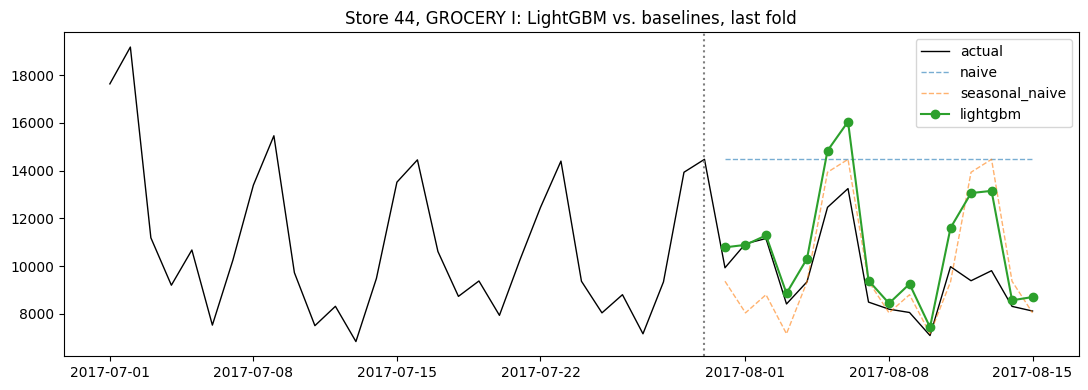

In [13]:
# Same example series as in Step 2, now with LightGBM
# Adım 2'deki aynı örnek seri, şimdi LightGBM ile
ex_l = lgb_pred[(lgb_pred.store_nbr == 44) & (lgb_pred.family == "GROCERY I")]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(hist.date, hist.sales, color="black", lw=1, label="actual")
for name, g in ex.groupby("model"):
    ax.plot(g.date, g.pred, ls="--", lw=1, alpha=0.6, label=name)
ax.plot(ex_l.date, ex_l.pred, marker="o", color="tab:green", label="lightgbm")
ax.axvline(last.cutoff, color="grey", ls=":")
ax.set_title("Store 44, GROCERY I: LightGBM vs. baselines, last fold"); ax.legend()
plt.tight_layout(); plt.savefig(data.FIG_DIR / "03_lightgbm_example.png", dpi=110); plt.show()

## Step 4: Rolling-window backtest / Adım 4: Kayan pencereli backtest
**EN:** In each of 4 folds, LightGBM is retrained on data up to the cutoff and forecasts the next 16 days. Four folds show whether the gain is stable.

**TR:** 4 fold'un her birinde LightGBM cutoff'a kadarki veriyle yeniden eğitilir ve sonraki 16 günü tahmin eder. Dört fold, kazancın istikrarlı olup olmadığını gösterir.

In [14]:
from src import backtest

# Retrain + forecast per fold (about 15 s per fold on a laptop CPU)
# Her fold için yeniden eğit + tahmin et (laptop CPU'sunda fold başına ~15 sn)
res = backtest.run_backtest(df, feat, folds)
res.to_parquet(ROOT / "reports" / "backtest_preds.parquet")  # used in Step 6 / Adım 6'da kullanılır

fold 1 done in 11.5s


fold 2 done in 12.5s


fold 3 done in 12.2s


fold 4 done in 16.9s


In [15]:
# Main results table: WAPE / MAE / RMSE per fold and model
# Ana sonuç tablosu: fold ve model başına WAPE / MAE / RMSE
sc = backtest.score(res)
table = sc.pivot(index="fold", columns="model", values=["WAPE", "MAE", "RMSE"])
table.loc["mean"] = table.mean()
order = ["naive", "seasonal_naive", "lightgbm"]
table = table.reindex(columns=pd.MultiIndex.from_product([["WAPE", "MAE", "RMSE"], order]))
table.round(3).to_csv(ROOT / "reports" / "backtest_metrics.csv")
gain = 1 - table[("WAPE", "lightgbm")] / table[("WAPE", "seasonal_naive")]
print("LightGBM WAPE improvement vs seasonal naive per fold:", (gain * 100).round(1).to_dict())
table.round(3)

LightGBM WAPE improvement vs seasonal naive per fold: {1: 31.0, 2: 38.6, 3: 12.9, 4: 32.3, 'mean': 29.5}


WAPE                              MAE                              RMSE                        
      naive seasonal_naive lightgbm    naive seasonal_naive lightgbm     naive seasonal_naive lightgbm
fold                                                                                                  
1     0.225          0.162    0.112  316.016        227.921  157.285   716.284        532.965  393.092
2     0.298          0.156    0.096  444.873        232.726  142.944  1039.506        579.011  356.865
3     0.259          0.132    0.115  383.811        195.402  170.197   857.639        482.172  387.540
4     0.438          0.197    0.133  627.933        282.462  191.102  1313.135        628.457  407.279
mean  0.305          0.162    0.114  443.158        234.628  165.382   981.641        555.651  386.194

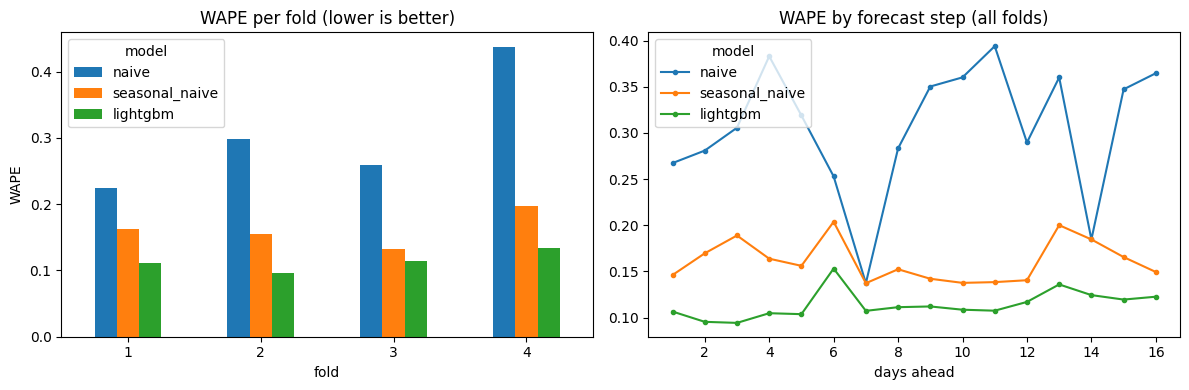

In [16]:
# WAPE per fold (left) and by forecast step 1..16 (right)
# Fold başına WAPE (sol) ve tahmin adımına göre 1..16 (sağ)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sc.pivot(index="fold", columns="model", values="WAPE")[order].plot.bar(ax=ax[0], rot=0)
ax[0].set_title("WAPE per fold (lower is better)"); ax[0].set_ylabel("WAPE")
by_h = backtest.score(res, by=("h", "model")).pivot(index="h", columns="model", values="WAPE")[order]
by_h.plot(ax=ax[1], marker=".")
ax[1].set_title("WAPE by forecast step (all folds)"); ax[1].set_xlabel("days ahead")
plt.tight_layout(); plt.savefig(data.FIG_DIR / "04_backtest_wape.png", dpi=110); plt.show()

In [17]:
# Where is LightGBM better or worse? WAPE by family (all folds)
# LightGBM nerede daha iyi veya kötü? Aileye göre WAPE (tüm fold'lar)
by_fam = backtest.score(res, by=("family", "model")).pivot(index="family", columns="model", values="WAPE")[order]
by_fam["gain_vs_snaive_%"] = (1 - by_fam.lightgbm / by_fam.seasonal_naive) * 100
by_fam.sort_values("gain_vs_snaive_%").round(3)

model,naive,seasonal_naive,lightgbm,gain_vs_snaive_%
family,,,,
PRODUCE,0.288,0.098,0.085,13.226
DAIRY,0.249,0.118,0.100,14.609
BREAD/BAKERY,0.243,0.125,0.106,15.067
MEATS,0.366,0.151,0.121,19.978
DELI,0.304,0.166,0.123,25.956
POULTRY,0.355,0.155,0.113,27.245
BEVERAGES,0.334,0.185,0.133,27.905
GROCERY I,0.264,0.147,0.095,35.503
PERSONAL CARE,0.377,0.237,0.145,38.738


## Step 5: SHAP explanations / Adım 5: SHAP açıklamaları
**EN:** SHAP splits each prediction into feature contributions, computed on 5,000 rows from the 90 days before the last cutoff. Values are in `log1p(sales)`, so +0.10 is about +10% sales.

**TR:** SHAP her tahmini özellik katkılarına ayırır; son cutoff'tan önceki 90 günden 5.000 satır üzerinde hesaplanır. Değerler `log1p(satış)` ölçeğinde, yani +0.10 yaklaşık +%10 satış.

In [18]:
import shap
from src import explain

# Explain the last-fold model on recent training rows
# Son fold modelini yakın tarihli eğitim satırları üzerinde açıkla
tr_rows = model.training_rows(feat, last.cutoff)
X_shap = tr_rows[tr_rows.date > last.cutoff - pd.Timedelta(days=90)].sample(5000, random_state=0)
exp = explain.shap_values(lgb_model, X_shap)

# Check: base value + SHAP values = model prediction
# Kontrol: başlangıç değeri + SHAP değerleri = model tahmini
import numpy as np
print("max additivity error:", np.abs(exp.values.sum(1) + exp.base_values - lgb_model.predict(X_shap[features.FEATURES])).max())

max additivity error: 4.973799150320701e-14


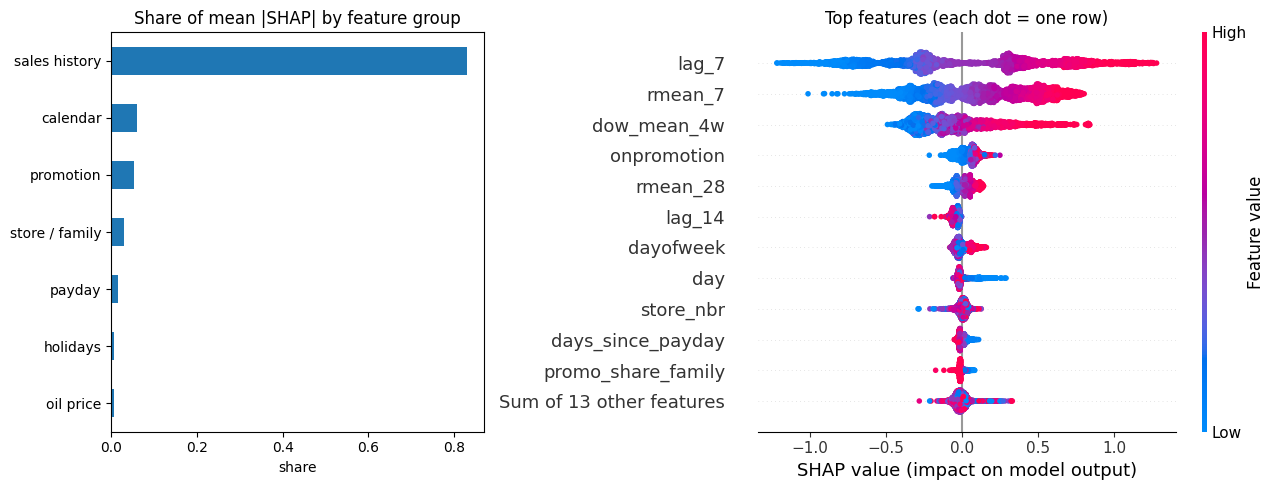

sales history     0.830
calendar          0.059
promotion         0.054
store / family    0.029
payday            0.015
holidays          0.006
oil price         0.006
dtype: float64

In [19]:
# Importance by feature group (share of mean |SHAP|)
# Özellik grubuna göre önem (ortalama |SHAP| payı)
grp = explain.group_importance(exp)
fig, ax = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1, 1.4]})
grp.sort_values().plot.barh(ax=ax[0], color="tab:blue")
ax[0].set_title("Share of mean |SHAP| by feature group"); ax[0].set_xlabel("share")
plt.sca(ax[1])
shap.plots.beeswarm(exp, max_display=12, show=False, plot_size=None)
ax[1].set_title("Top features (each dot = one row)")
plt.tight_layout(); plt.savefig(data.FIG_DIR / "05_shap_summary.png", dpi=110, bbox_inches="tight"); plt.show()
grp.round(3)

In [20]:
# Mean SHAP when a rare flag is on vs. off
# Nadir bir bayrak açıkken ve kapalıyken ortalama SHAP
rows = []
for col, cond in [("onpromotion", X_shap.onpromotion > 0), ("hol_national", X_shap.hol_national == 1),
                  ("hol_local", X_shap.hol_local == 1), ("is_payday", X_shap.is_payday == 1)]:
    i = features.FEATURES.index(col)
    rows.append({"feature": col, "rows_with_flag": int(cond.sum()),
                 "mean_shap_when_on": exp.values[cond.values, i].mean(),
                 "mean_shap_when_off": exp.values[~cond.values, i].mean()})

# Payday is in two features, so sum their SHAP values
# Maaş günü iki özellikte, bu yüzden SHAP değerlerini topla
pay = exp.values[:, features.FEATURES.index("is_payday")] + exp.values[:, features.FEATURES.index("days_since_payday")]
on = (X_shap.is_payday == 1).values
rows.append({"feature": "payday (is_payday + days_since_payday)", "rows_with_flag": int(on.sum()),
             "mean_shap_when_on": pay[on].mean(), "mean_shap_when_off": pay[~on].mean()})
pd.DataFrame(rows).round(3)

,feature,rows_with_flag,mean_shap_when_on,mean_shap_when_off
0,onpromotion,4114,0.051,-0.058
1,hol_national,124,0.104,-0.004
2,hol_local,30,-0.013,0.000
3,is_payday,285,-0.008,0.001
4,payday (is_payday + days_since_payday),285,0.028,-0.002


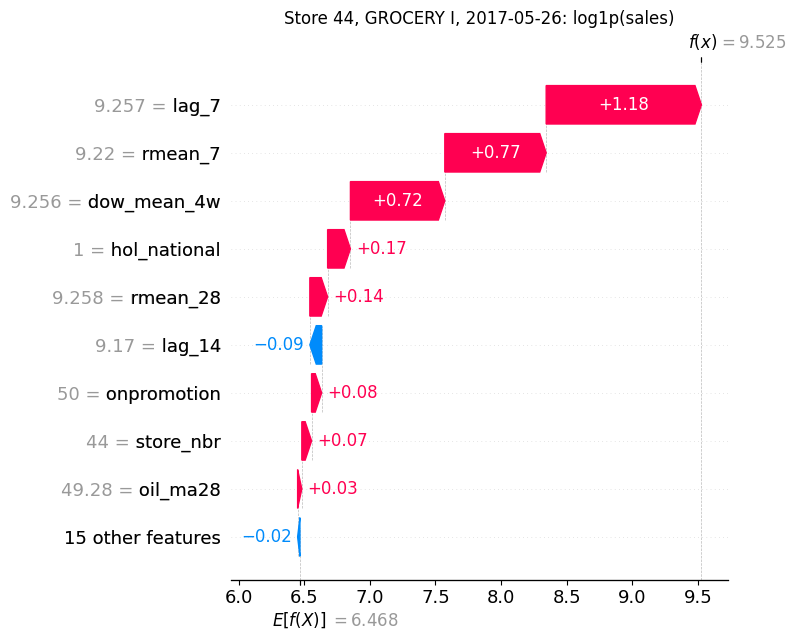

In [21]:
# One prediction explained: store 44, GROCERY I on 2017-05-26 (transferred national holiday)
# Tek tahminin açıklaması: mağaza 44, GROCERY I, 26.05.2017 (taşınan ulusal tatil)
one = feat[(feat.store_nbr == 44) & (feat.family == "GROCERY I") & (feat.date == "2017-05-26")]
e1 = explain.shap_values(lgb_model, one)
shap.plots.waterfall(e1[0], max_display=10, show=False)
plt.title("Store 44, GROCERY I, 2017-05-26: log1p(sales)")
plt.tight_layout(); plt.savefig(data.FIG_DIR / "05_shap_waterfall.png", dpi=110, bbox_inches="tight"); plt.show()

## Step 6: Inventory simulation / Adım 6: Stok simülasyonu
**EN:** There is no real stock data, so this simulation uses recorded sales as demand. Every evening each method orders up to its 4-day forecast plus safety stock, with a 3-day lead time and lost sales.

**TR:** Gerçek stok verisi yok, bu yüzden simülasyon kayıtlı satışları talep olarak kullanır. Her akşam her yöntem 4 günlük tahmin artı emniyet stoğuna kadar sipariş verir; tedarik süresi 3 gün, karşılanamayan talep kaybolur.

In [22]:
from src import inventory as inv

# Simulation = the 64 backtest days; orders after 08-11 cannot arrive in time
# Simülasyon = 64 backtest günü; 11.08'den sonraki siparişler zamanında gelemez
sim_days = pd.date_range(folds.test_start.iloc[0], folds.test_end.iloc[-1])
first_cut = sim_days[0] - pd.Timedelta(days=1)
sim_cutoffs = pd.date_range(first_cut, sim_days[-1] - pd.Timedelta(days=inv.LEAD_TIME + 1))

# Calibration period before the simulation, also retrained every 16 days
# Simülasyondan önceki kalibrasyon dönemi, o da 16 günde bir yeniden eğitilir
cal_retrain = [first_cut - pd.Timedelta(days=16 * k) for k in (3, 2, 1)]
cal_cutoffs = pd.date_range(cal_retrain[0], first_cut - pd.Timedelta(days=inv.PROTECTION))
print("simulation:", sim_days[0].date(), "->", sim_days[-1].date(), f"({len(sim_days)} days)")
print("calibration cutoffs:", cal_cutoffs[0].date(), "->", cal_cutoffs[-1].date())

simulation: 2017-06-13 -> 2017-08-15 (64 days)
calibration cutoffs: 2017-04-25 -> 2017-06-08


In [23]:
# 4-day forecasts every day for each method (about 3 minutes)
# Her gün her yöntem için 4 günlük tahmin (yaklaşık 3 dakika)
fc_cal = inv.daily_forecasts(df, feat, cal_cutoffs, cal_retrain)
fc_sim = inv.daily_forecasts(df, feat, sim_cutoffs, folds.cutoff)
sigma = inv.error_sigma(fc_cal, inv.protection_actuals(df, cal_cutoffs))

# How good are the 4-day forecasts inside the simulation?
# Simülasyon içinde 4 günlük tahminler ne kadar iyi?
chk = fc_sim.merge(inv.protection_actuals(df, sim_cutoffs), on=["cutoff", "store_nbr", "family"])
chk.groupby("method").apply(lambda g: pd.Series({
    "WAPE_4day": (g.fc_sum - g.actual_sum).abs().sum() / g.actual_sum.sum(),
    "bias_%": 100 * (g.fc_sum.sum() / g.actual_sum.sum() - 1),
    "sum_sigma": sigma.loc[sigma.method == g.name, "sigma"].sum()}), include_groups=False).round(3)

45 daily cutoffs in 81s


61 daily cutoffs in 84s


,WAPE_4day,bias_%,sum_sigma
method,,,
lightgbm,0.071,0.662,360987.360
naive,0.255,-0.222,1167784.758
seasonal_naive,0.122,1.235,552202.077


In [24]:
# Main result (95%) and what-if (90% / 99%)
# Ana sonuç (%95) ve senaryo (%90 / %99)
sim = pd.concat([inv.run(df, fc_sim, sigma, sim_days, sl) for sl in (0.90, 0.95, 0.99)], ignore_index=True)
sim.to_csv(ROOT / "reports" / "inventory_simulation.csv", index=False)
view = sim.set_index(["service_level", "method"])[["fill_rate", "avg_inventory", "days_of_cover", "stockout_days_%"]]
view.style.format({"fill_rate": "{:.2%}", "avg_inventory": "{:,.0f}", "days_of_cover": "{:.2f}", "stockout_days_%": "{:.1f}"})

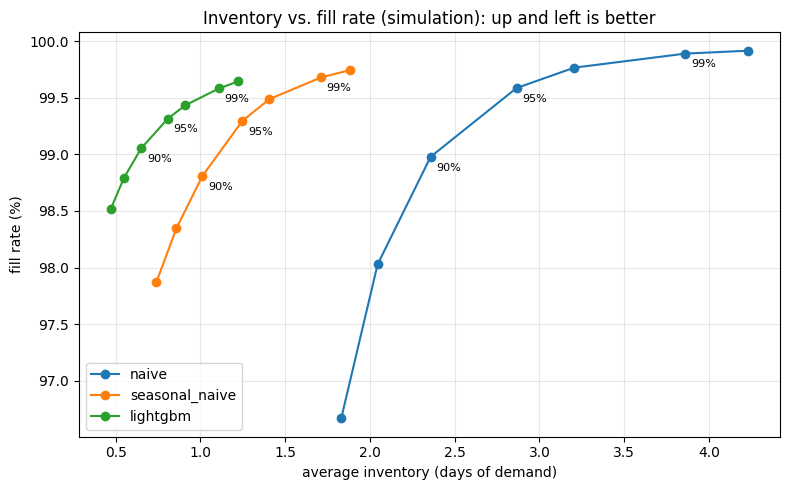

days of inventory needed for 99.5% fill rate: {'naive': 2.79, 'seasonal_naive': 1.43, 'lightgbm': 1.0}


In [25]:
# Fill rate vs. inventory over many service levels
# Birçok servis seviyesinde fill rate ve stok
levels = [0.80, 0.85, 0.90, 0.95, 0.97, 0.99, 0.995]
curve = pd.concat([inv.run(df, fc_sim, sigma, sim_days, sl) for sl in levels], ignore_index=True)
order = ["naive", "seasonal_naive", "lightgbm"]
fig, ax = plt.subplots(figsize=(8, 5))
for mth in order:
    g = curve[curve.method == mth]
    ax.plot(g.days_of_cover, 100 * g.fill_rate, marker="o", label=mth)
    for sl in (0.90, 0.95, 0.99):
        r = g[g.service_level == sl].iloc[0]
        ax.annotate(f"{sl:.0%}", (r.days_of_cover, 100 * r.fill_rate), textcoords="offset points", xytext=(4, -10), fontsize=8)
ax.set_xlabel("average inventory (days of demand)"); ax.set_ylabel("fill rate (%)")
ax.set_title("Inventory vs. fill rate (simulation): up and left is better"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(data.FIG_DIR / "06_inventory_tradeoff.png", dpi=110); plt.show()

# Inventory needed to reach the same fill rate (interpolated on the curve)
# Aynı fill rate'e ulaşmak için gereken stok (eğri üzerinde ara değer)
target_fr = 0.995
need = {mth: np.interp(target_fr, curve[curve.method == mth].fill_rate, curve[curve.method == mth].days_of_cover) for mth in order}
print(f"days of inventory needed for {target_fr:.1%} fill rate:", {k: round(v, 2) for k, v in need.items()})

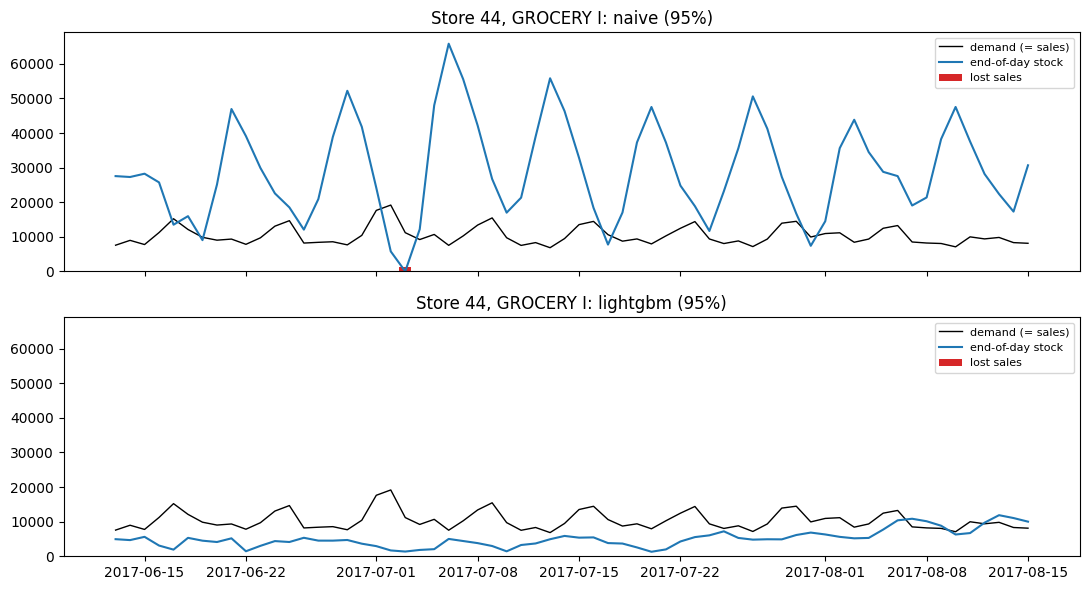

In [26]:
# One series over time: stock and lost sales, naive vs. LightGBM (95%)
# Tek seri zaman içinde: stok ve kayıp satış, naive ve LightGBM (%95)
fig, ax = plt.subplots(2, 1, figsize=(11, 6), sharex=True, sharey=True)
for a, mth in zip(ax, ["naive", "lightgbm"]):
    dem, sold, stock = inv.simulate_method(df, fc_sim, sigma, sim_days, mth, 0.95)
    i = dem.index.get_loc((44, "GROCERY I"))
    a.plot(sim_days, dem.iloc[i].values, color="black", lw=1, label="demand (= sales)")
    a.plot(sim_days, stock[i], color="tab:blue", label="end-of-day stock")
    lost = dem.iloc[i].values - sold[i]
    a.bar(sim_days, lost, color="tab:red", label="lost sales")
    a.set_title(f"Store 44, GROCERY I: {mth} (95%)"); a.legend(loc="upper right", fontsize=8)
plt.tight_layout(); plt.savefig(data.FIG_DIR / "06_inventory_example.png", dpi=110); plt.show()